# MAE O3 · learned 16-step schedule scoring

**Complete** · Study complete.

Updated 2026-11-24T18:03:56+01:00.

## Experiment

The scorer receives the learner's pre-block state summary, features for all 16 available images,
and the order of the candidate actions. Its ridge model predicts differences in terminal O3 cost.
Training labels are exact scratch rollouts from the [eight-schedule planning pilot](MAE_O3_16_Step_Schedule_Planning.ipynb).
Weights for each seed are fit on the other two seeds. The registered walks reuse some images across
seeds, so the holdout is by learner trajectory. Archived trajectories are replayed to reconstruct
pre-block features and verify their saved readouts. Each seed uses 128 blocks.

The offline test ranks the original eight schedules on unseen seeds. Every eighth archived block also
scores eight previously unseen schedules exactly, so that test asks whether the scorer can rank new
orders as well. All schedules preserve the same four skips, eight quarter updates and four full updates.

In the live comparison, **Scorer** commits its predicted winner. **Exact top two** rolls out the two
highest-ranked schedules and commits the one with lower measured O3 cost. Both live arms consider the
original eight options and learn from one full eight-schedule audit per 16 blocks. Each audit is
incorporated after the decision and execution. The learner sees the complete image block at selection time.

## Held-out forecasts

| Held-out seed | Original top-1 hit | Original top-2 hit | Expanded top-2 hit | Unseen winners retained | Original scorer regret | Original top-2 regret |
| --- | ---: | ---: | ---: | ---: | ---: | ---: |
| 2026 | 14.1% | 31.2% | 25.0% | 3/8 | 0.0673 | 0.0446 |
| 2027 | 20.3% | 38.3% | 25.0% | 0/3 | 0.0892 | 0.0541 |
| 2028 | 16.4% | 28.1% | 12.5% | 1/6 | 0.0782 | 0.0427 |

A hit means the measured winner was present. Regret is the chosen schedule’s measured cost above the per-block winner. Expanded tests use the audited subset of blocks.

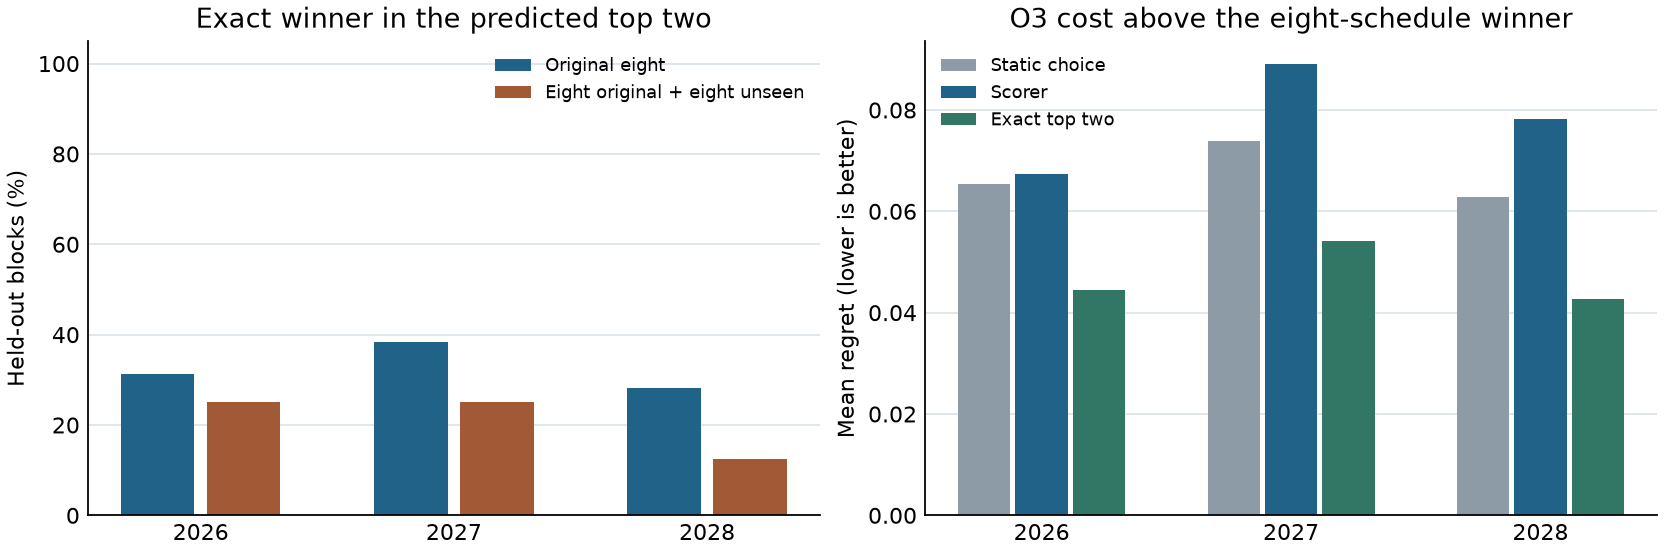

### Same-budget shortlist comparison

Every method gets two exact rollouts, then selects the better measured schedule.
The fixed pair comprises the two lowest average-cost schedules on the other two seeds.
Uniform-random results are averages over every unordered pair per block.

| Candidate set | Shortlist | Exact winner retained | O3 regret |
| --- | --- | ---: | ---: |
| Original | Random pair | 25.0% | 0.0498 |
| Original | Fixed pair | 36.5% | 0.0385 |
| Original | Learned pair | 32.6% | 0.0471 |
| Expanded | Random pair | 12.5% | 0.0580 |
| Expanded | Fixed pair | 18.8% | 0.0391 |
| Expanded | Learned pair | 20.8% | 0.0551 |

The fixed pair had lower mean regret than the learned pair in both offline ranking tests.
For the expanded library, an unseen schedule was the exact winner in 17 of 48 blocks and
the learned shortlist retained 4 of those 17 winners. The fixed pair was evaluated on
archived block states. Its prospective probe result remains open.


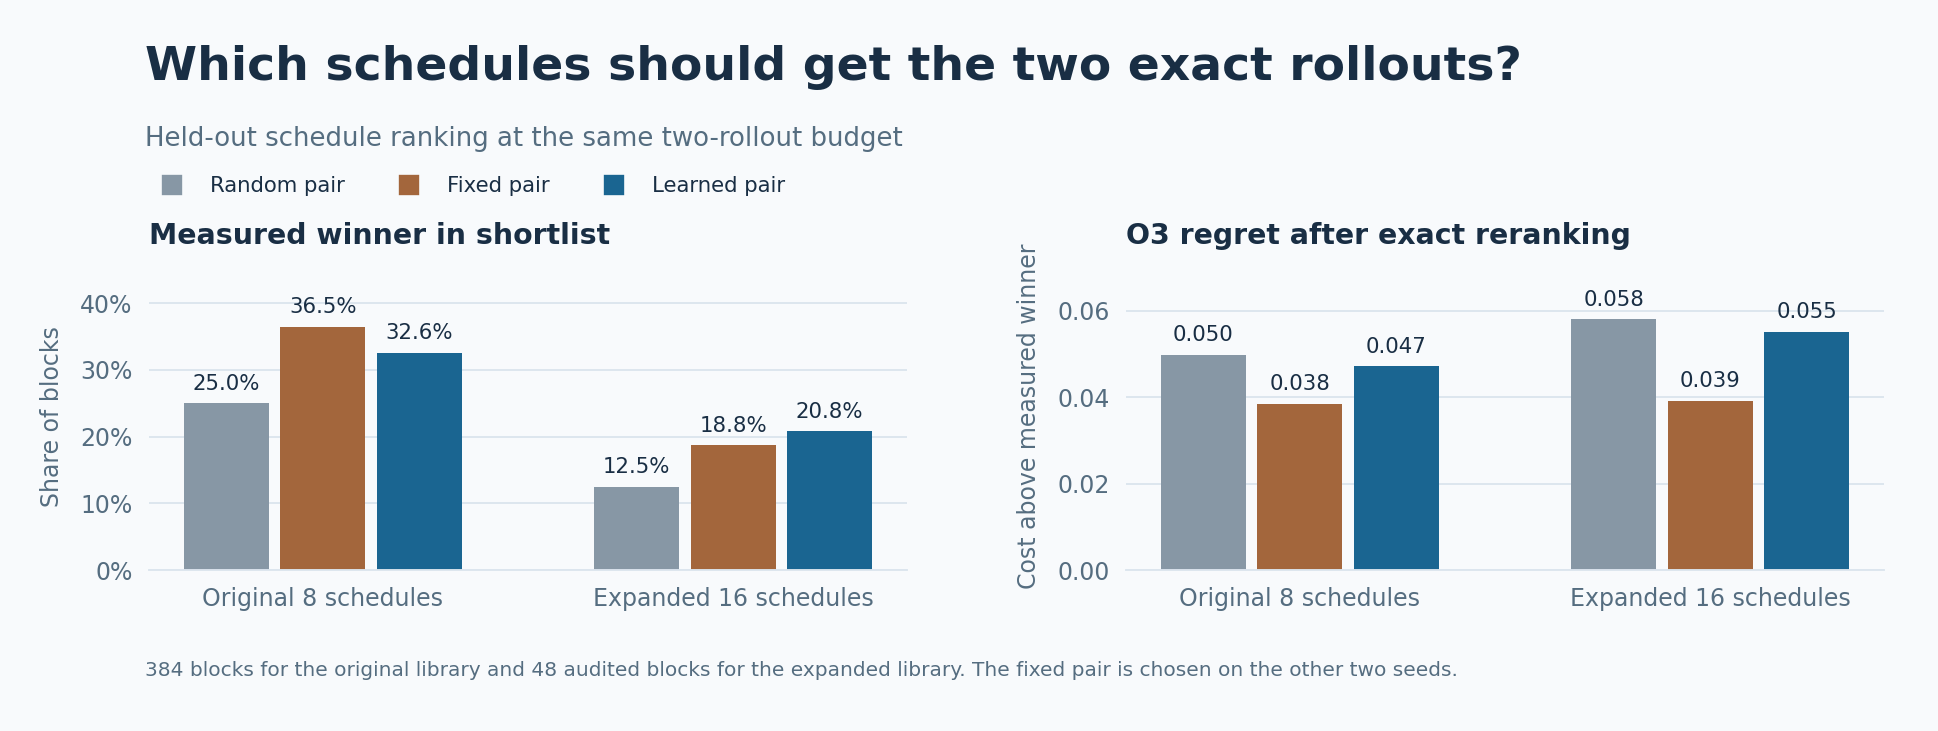

## Prospective outcomes

| Seed | Arm | Mean endpoint probe | Change vs shuffle | Live time | Exact schedules evaluated |
| --- | --- | ---: | ---: | ---: | ---: |
| 2026 | scorer | 60.69% | -0.21 pp | 15.4 s | 64 |
| 2026 | top-two | 60.97% | +0.07 pp | 21.2 s | 304 |
| 2027 | scorer | 60.75% | +0.15 pp | 16.6 s | 64 |
| 2027 | top-two | 61.02% | +0.41 pp | 20.6 s | 304 |
| 2028 | scorer | 60.53% | +0.33 pp | 19.5 s | 64 |
| 2028 | top-two | 60.40% | +0.20 pp | 21.1 s | 304 |

Mean endpoint probes and mean timed seconds per seed:
- scorer: 60.66% and 17.2 s.
- top-two: 60.80% and 21.0 s.
- planner: 60.90% and 30.4 s.
- shuffle: 60.57% and 12.6 s.

Timing includes online features, exact audits and updates. Probe measurements and offline training are outside the timed interval. The endpoint averages five held-out probes.

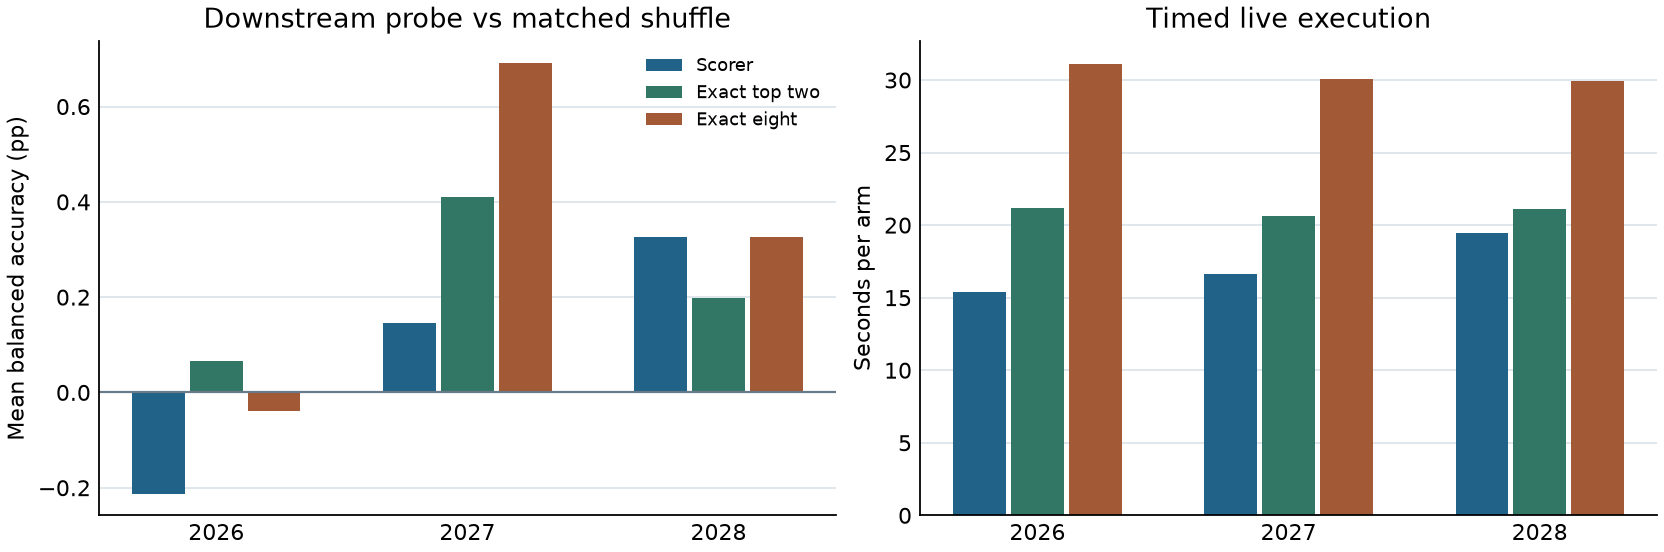

## Files

Reopen this notebook for the latest saved progress. The [runner](../../../../../analysis/2026-11-09-one-step-mpc/mae-p12-online16/run_block_schedule_scorer.py)
and [run records](../../../../../analysis/2026-11-09-one-step-mpc/mae-p12-online16/block-schedule-scorer/pilot-2048/)
include the paired measurements, individual trajectories and timing.